In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

In [ ]:
faces = fetch_olivetti_faces()

X = faces.images
y = faces.target

print("Total Images:", len(X))
print("Number of People:", len(np.unique(y)))
print("Image Size:", X.shape[1:])

Total Images: 400
Number of People: 40
Image Size: (64, 64)


In [ ]:
X = X.reshape(-1, 64, 64, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)

Training Images: (320, 64, 64, 1)
Testing Images: (80, 64, 64, 1)


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(40, activation='softmax')
])

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.1
)

Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 117ms/step - accuracy: 0.0208 - loss: 3.7309 - val_accuracy: 0.0000e+00 - val_loss: 3.6937
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 144ms/step - accuracy: 0.0208 - loss: 3.6826 - val_accuracy: 0.0000e+00 - val_loss: 3.7091
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - accuracy: 0.0556 - loss: 3.6561 - val_accuracy: 0.0000e+00 - val_loss: 3.6833
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 179ms/step - accuracy: 0.1042 - loss: 3.5893 - val_accuracy: 0.0000e+00 - val_loss: 3.6645
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 145ms/step - accuracy: 0.1701 - loss: 3.3674 - val_accuracy: 0.0938 - val_loss: 3.5318
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - accuracy: 0.3229 - loss: 2.8567 - val_accuracy: 0.1250 - val_loss: 3.1060
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.4479 - loss: 2.2239 - val_accuracy: 0.2500 - val_loss: 2.5546
Epoch 8/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.6042 - loss: 1.5081 - va

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_acc * 100, "%")
print("Test Loss:", test_loss)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9375 - loss: 0.1819
Test Accuracy: 93.75 %
Test Loss: 0.1818857192993164


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


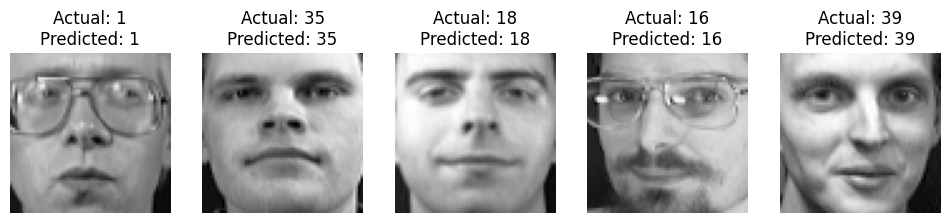

In [ ]:
predictions = model.predict(X_test[:5])

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[i].reshape(64, 64), cmap='gray')

    predicted_person = np.argmax(predictions[i])

    plt.title("Actual: " + str(y_test[i]) +
              "\nPredicted: " + str(predicted_person))

    plt.axis('off')

plt.show()

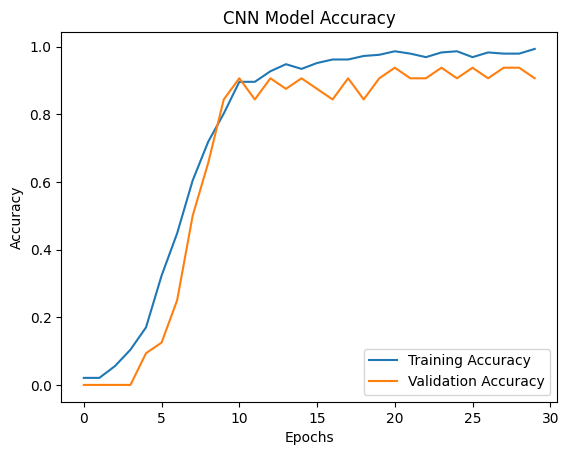

In [ ]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('CNN Model Accuracy')
plt.legend()
plt.show()